# Hari 1, Sesi 0: Persiapan Google Colab untuk Ekonometrika

**Durasi:** 30 menit

Notebook ini untuk dosen atau pengajar. Isinya: menyiapkan lingkungan kerja,
menyiapkan data, dan mengenali padanan perintah EViews dengan Python.

**Sebelum mulai:** notebook ini membaca file CSV dari folder `data/`.
Kalau folder itu belum ada, unggah `data_tutorial.zip` lewat panel
Files di kiri layar Colab, lalu jalankan sel pertama di bawah sekali.
Di komputer sendiri, biarkan struktur folder proyek tetap utuh.

Cara menjalankan sel: klik selnya, tekan `Shift + Enter`.



**Posisi dalam alur workshop.** Sesi pembuka: menyiapkan alat dan data.
Semua sesi setelah ini memakai pola yang sama, yaitu muat data, estimasi
model, baca output, uji, lalu interpretasi.



## Cara mengikuti notebook ini

Jalankan sel berurutan dengan `Shift + Enter`. Setiap notebook dapat
dimulai sendiri setelah paket data diunggah. Sel persiapan cukup dijalankan
apa adanya; fokus latihan dimulai saat tabel data muncul.

Baca penjelasan sebelum menjalankan kode, lalu sebutkan arti hasilnya.
Ubah satu hal setiap mencoba: nama kolom pada X, pilihan model, atau nilai prediksi.
Baris `#` adalah catatan. `=` menyimpan hasil dan `==` membandingkan nilai.
Contoh `tabel["kolom"]` berarti memilih satu kolom dari tabel.

Jika muncul error merah, berhenti di sel itu dan baca baris terakhirnya.
Jika ada warning, baca pesannya dan periksa hasil estimasi sebelum lanjut.
Panduan simbol dan contoh tambahan ada di `panduan/01_panduan_pemula.md`.



### Pola pemodelan yang dipakai

`X` adalah tabel fitur dan `y` adalah kolom target. Model utama memakai
scikit-learn: buat model, jalankan `fit(X, y)`, lalu gunakan `predict(X_baru)`.
Koefisien ada pada `coef_` dan intersep pada `intercept_`. Tabel `koefisien_...`
hanya memberi nama kolom agar angka mudah dibaca. `score(X, y)` pada regresi
linear adalah R² pada data yang diberikan; hasil pada data latih belum mengukur
kemampuan memprediksi data baru.

Nama `uji_...` menandai pelengkap statistik untuk p-value, standard error, atau
uji asumsi. Perhitungannya memakai X dan y yang sama. Bagian model khusus diberi
catatan tersendiri ketika scikit-learn belum menyediakan estimatornya.



In [1]:
import os
import zipfile
from pathlib import Path

# Di komputer sendiri, temukan folder data dari lokasi notebook ini.
# Di Colab, folder kerja tetap memakai lokasi unggahan Anda.
if not Path("data").is_dir() and Path("../../data").is_dir():
    os.chdir("../..")

# Jalankan apa adanya. Paket dibuka jika alat bantu belum tersedia.
# Jika data sudah siap, menjalankan ulang sel ini tidak menimpa CSV.
if (
    Path("data_tutorial.zip").exists()
    and not Path("alat_bantu/metode_lanjutan.py").exists()
):
    with zipfile.ZipFile("data_tutorial.zip") as paket:
        paket.extractall(".")

if not Path("data/uts_2.csv").exists():
    raise FileNotFoundError(
        "Unggah data_tutorial.zip lewat panel Files di kiri Colab, "
        "lalu jalankan sel ini lagi."
    )

print("Data siap. Lanjutkan ke sel berikutnya.")



Data siap. Lanjutkan ke sel berikutnya.


## 1. Cek lingkungan

Colab sudah menyediakan pandas, statsmodels, matplotlib, dan seaborn.
Dua paket tambahan yang belum ada dipasang sekali di bawah ini:
`linearmodels` untuk data panel (Sesi 6) dan `arch` untuk GARCH.



In [2]:
%pip install "linearmodels==7.1" "arch==8.0.0" -q



Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "font.size": 11})

print("Python", sys.version.split()[0])
print("pandas", pd.__version__)
print("statsmodels", sm.__version__)
print("scikit-learn", sklearn.__version__)



Python 3.13.5
pandas 2.2.3
statsmodels 0.15.0
scikit-learn 1.6.1


## 2. Baca data pertama

Semua data ada di folder `data/`. Cara membacanya selalu satu baris:
`pd.read_csv("data/regresi_polinom.csv")`.



In [4]:
data = pd.read_csv("data/regresi_polinom.csv")
print("Ukuran data:", data.shape)
data.head()



Ukuran data: (30, 3)


,Tahun ke-,Biaya Iklan (X),Penjualan (Y)
0,1,5.0,30.1
1,2,6.5,36.2
2,3,8.0,42.5
3,4,9.5,48.8
4,5,11.0,54.1


## 3. Sel pertama yang berguna: satu grafik

Sebelum masuk regresi, lihat datanya dulu. Satu scatter plot bisa
menyelamatkan Anda dari salah spesifikasi yang mahal.



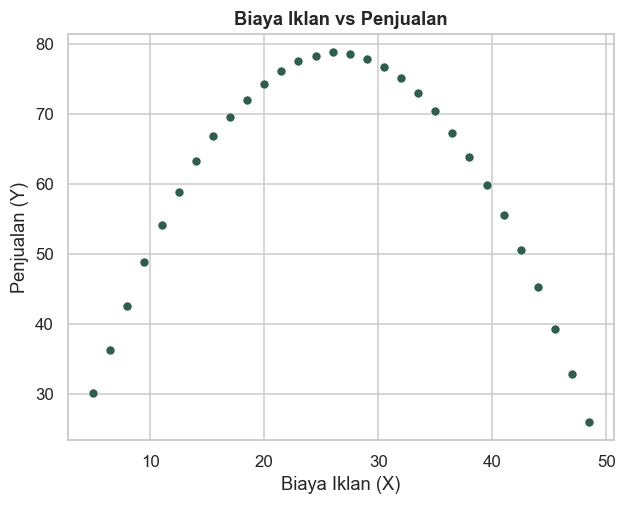

In [5]:
sns.scatterplot(data=data, x="Biaya Iklan (X)", y="Penjualan (Y)")
plt.title("Biaya Iklan vs Penjualan")
plt.show()



## 4. Membaca rumus model dan angka penting

Simbol `~` dibaca "dijelaskan oleh". Jadi `penjualan ~ iklan` berarti
penjualan dijelaskan oleh iklan. `fit()` menghitung koefisiennya.
Di sini model garis lurus hanya contoh awal; bentuk lengkung dibahas di Sesi 2.



In [6]:
polinom = data.rename(
    columns={"Biaya Iklan (X)": "iklan", "Penjualan (Y)": "penjualan"}
)
sampel_model = polinom[["penjualan", "iklan"]].dropna()
X_model = sampel_model[["iklan"]]
y_model = sampel_model["penjualan"]

model = LinearRegression()
model.fit(X_model, y_model)

# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model = sm.OLS(
    y_model,
    sm.add_constant(X_model, has_constant="add").rename(columns={"const": "Intercept"}),
).fit()



In [7]:
# Baca satu angka setiap baris. Tidak perlu membuat fungsi Python sendiri.
print("Jumlah observasi:", uji_model.nobs)
print("R kuadrat:", model.score(X_model, y_model))
print("R kuadrat terkoreksi:", uji_model.rsquared_adj)
print("p-value uji F:", uji_model.f_pvalue)
print("AIC:", uji_model.aic)



Jumlah observasi: 30.0
R kuadrat: 0.0065772980467725395
R kuadrat terkoreksi: -0.0289020841658425
p-value uji F: 0.670083095460895
AIC: 255.84470425068557


### Coba sendiri (5 menit)

Baca `data/uts_4.csv` ke variabel baru, lalu tampilkan jumlah baris dan
rata-rata kolom `Y_Angka_Harapan_Hidup`. Butuh berapa baris kode?

Tulis di sel di bawah, baru buka jawabannya.



In [8]:
# Tulis kode Anda di sini



<details><summary>Lihat jawaban</summary>

Dua baris: `uts4 = pd.read_csv("data/uts_4.csv")` lalu
`print(len(uts4), uts4["Y_Angka_Harapan_Hidup"].mean())`.
Hasilnya 50 baris dan rata-rata 76,95.

</details>



## 5. Padanan perintah EViews dan Python

Materi kuliah memakai EViews. Tabel ini jembatannya:

| EViews | Python dalam tutorial |
|---|---|
| `ls y c x1 x2` | `LinearRegression().fit(X, y)`; X berisi x1 dan x2 |
| `ls log(y) c log(x)` | Buat kolom log, lalu `LinearRegression().fit(X_log, y_log)` |
| Method **BINARY - Logit** | `LogisticRegression().fit(X, y)` |
| Method **BINARY - Probit** | `smf.probit("y ~ x1", data=df).fit()` |
| Method **ORDERED** | `OrderedModel(...)` dari statsmodels |
| Method **COUNT - Poisson** | `PoissonRegressor(alpha=0).fit(X, y)` |
| Method **ARCH - GARCH(1,1)** | `arch_model(y, vol="Garch", p=1, q=1)` |
| Options > White robust SE | `.fit(cov_type="HC3")` |
| Panel Options: Fixed | `PanelOLS(..., entity_effects=True)` |

Nama kolom output juga beda, artinya sama:

| EViews | statsmodels | Arti |
|---|---|---|
| Coefficient | `coef` | koefisien |
| Std. Error | `std err` | galat baku |
| t-Statistic | `t` | statistik uji |
| Prob. | `pvalue` (ditulis P di output) | p-value |
| R-squared | `rsquared` | proporsi variasi terjelaskan |

### Dua pustaka Python dan porsinya

- **scikit-learn**: model utama, koefisien, prediksi, pembagian data,
  dan evaluasi. Polanya sama: X, y, model, fit, predict.
- **statsmodels**: pelengkap inferensi dan diagnostik, serta model khusus
  seperti probit, ordinal, dan ARIMA. Data panel memakai **linearmodels**,
  sedangkan GARCH memakai **arch**.

OLS tetap metode estimasi `LinearRegression`. Nama `uji_...` membantu
membedakan pelengkap statistik dari model utama scikit-learn.

## 6. Peta materi semester ke notebook ini

| Pertemuan kuliah | Topik | Notebook |
|---|---|---|
| 1-2 | Regresi linear dan bentuk fungsional | `01`, `02` |
| 3-4 | Variabel dummy, multikolinearitas | `03` |
| 5-7 | Heteroskedastisitas, normalitas, autokorelasi | `03` |
| 9-10 | Logit, probit, multinomial, ordinal | `04` |
| 11 | Tobit dan Poisson | `04` |
| 12-13 | Deret waktu, kointegrasi, ECM | `05` |
| 14-15 | GARCH, data panel | `06` |

Dua hari tidak cukup menuntaskan 16 pertemuan. Yang dikejar di workshop
ini: alur kerja lengkap dari data sampai interpretasi, plus contoh kode
untuk setiap topik. Sisanya latihan mandiri.



## Latihan singkat

1. Baca `data/uts_4.csv` (data harapan hidup). Tampilkan 5 baris pertama.
2. Berapa jumlah observasi dan berapa rata-rata `Y_Angka_Harapan_Hidup`?

(Kunci ada di `pengajar/kunci_jawaban/catatan_latihan.md`.)



In [9]:
# Tulis jawaban Anda di sini
# uts4 = pd.read_csv("data/uts_4.csv")
# ...



## Praktik pendampingan AI

Setelah contoh regresi berjalan, salin satu sel dan minta AI:

> Saya baru belajar coding. Jelaskan kode ini satu baris setiap kali
> dalam bahasa Indonesia. Sebutkan masukannya, hasil yang disimpan,
> serta bagian yang boleh saya ubah. Gunakan nama yang sama dan
> jangan menambahkan fungsi buatan sendiri atau perulangan.

Cocokkan penjelasannya dengan tabel data dan hasil kode yang dijalankan.
AI tidak perlu menebak koefisien. Ganti satu nilai prediksi, jalankan ulang,
lalu tulis kesimpulan sendiri dengan satuan yang benar. Contoh prompt
untuk membaca output dan memahami error ada di panduan/02_panduan_ai.md.



### Selanjutnya

Selanjutnya: Sesi 1, model regresi pertama.
